In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import re
import unicodedata

from pathlib import Path

from sklearn.linear_model import RidgeClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)

N_STATES = 5
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

In [2]:
DATA_DIR = Path("../Data")
RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(exist_ok=True)

print("Data folder exists:", DATA_DIR.exists())

if not DATA_DIR.exists():
    raise FileNotFoundError("Data folder not found.")

print("Feature files:", len(list(DATA_DIR.glob("*_features.csv"))))
print("Processed files:", len(list(DATA_DIR.glob("*_processed.csv"))))

Data folder exists: True
Feature files: 26
Processed files: 26


In [3]:
def clean_name(name):
    name = unicodedata.normalize("NFKC", name)

    name = "".join(
        char for char in name
        if unicodedata.category(char) != "Cf"
    )

    return name.strip().lower()


def get_recording_key(filepath):

    name = clean_name(filepath.stem)

    name = re.sub(
        r"_(features|processed)$",
        "",
        name
    )

    if name.startswith("abduct"):
        movement = "abduction"

    elif name.startswith("elevate"):
        movement = "elevating"

    elif name.startswith("flex"):
        movement = "flexing"

    elif name.startswith("sitting"):
        movement = "sitting"

    elif name.startswith("standing"):
        movement = "standing"

    elif name.startswith("walking"):
        movement = "walking"

    else:
        return None

    match = re.search(r"z\s*(\d+)", name)

    if match:
        trial = int(match.group(1))

    elif movement == "standing":
        trial = 1

    else:
        return None

    return movement, trial


feature_files = {}
processed_files = {}

for filepath in DATA_DIR.glob("*_features.csv"):
    key = get_recording_key(filepath)

    if key is not None:
        if key in feature_files:
            raise ValueError(f"Duplicate feature file: {key}")
        feature_files[key] = filepath


for filepath in DATA_DIR.glob("*_processed.csv"):
    key = get_recording_key(filepath)

    if key is not None:
        if key in processed_files:
            raise ValueError(f"Duplicate processed file: {key}")
        processed_files[key] = filepath


common_keys = sorted(
    set(feature_files) & set(processed_files)
)

print("Matched recordings:", len(common_keys))

print("\nMissing processed recordings:")
print(sorted(set(feature_files) - set(processed_files)))

print("\nMissing feature recordings:")
print(sorted(set(processed_files) - set(feature_files)))

if not common_keys:
    raise ValueError("No matching recordings found.")

Matched recordings: 26

Missing processed recordings:
[]

Missing feature recordings:
[]


In [4]:
standing_key = ("standing", 1)

if standing_key not in processed_files:
    raise FileNotFoundError(
        "Standing processed file is missing."
    )


def accel_tilt_deg(df, side):

    x = pd.to_numeric(
        df[f"Thigh_{side}_Accel_X"],
        errors="coerce"
    ).to_numpy(dtype=float)

    y = pd.to_numeric(
        df[f"Thigh_{side}_Accel_Y"],
        errors="coerce"
    ).to_numpy(dtype=float)

    z = pd.to_numeric(
        df[f"Thigh_{side}_Accel_Z"],
        errors="coerce"
    ).to_numpy(dtype=float)

    return np.degrees(
        np.arctan2(
            np.sqrt(x**2 + y**2),
            z
        )
    )


standing = pd.read_csv(
    processed_files[standing_key]
)

neutral_L = np.nanmedian(
    accel_tilt_deg(standing, "L")
)

neutral_R = np.nanmedian(
    accel_tilt_deg(standing, "R")
)

if not np.isfinite([neutral_L, neutral_R]).all():
    raise ValueError("Invalid standing reference.")

print("Left neutral:", neutral_L)
print("Right neutral:", neutral_R)

Left neutral: 101.62686114319813
Right neutral: 101.0616092669301


In [5]:
def normalize_score(values):

    values = np.array(
        values,
        dtype=float,
        copy=True
    )

    values[~np.isfinite(values)] = np.nan

    if np.all(np.isnan(values)):
        return np.full_like(values, np.nan)

    high = np.nanpercentile(values, 95)

    if not np.isfinite(high) or high <= 0:
        return np.full_like(values, np.nan)

    return np.clip(values / high, 0, 1)


def score_to_state(scores):

    scores = np.array(
        scores,
        dtype=float,
        copy=True
    )

    states = np.full(scores.shape, np.nan)

    valid = np.isfinite(scores)

    states[valid] = np.clip(
        np.floor(scores[valid] * N_STATES),
        0,
        N_STATES - 1
    )

    return states


def generate_states(processed):

    result = processed.copy()

    tilt_L = accel_tilt_deg(result, "L")
    tilt_R = accel_tilt_deg(result, "R")

    movement_L = np.abs(tilt_L - neutral_L)
    movement_R = np.abs(tilt_R - neutral_R)

    score_L = normalize_score(movement_L)
    score_R = normalize_score(movement_R)

    result["State_L"] = score_to_state(score_L)
    result["State_R"] = score_to_state(score_R)

    return result


print("State-generation functions ready.")

State-generation functions ready.


In [6]:
all_aligned = []
alignment_report = []

for key in common_keys:

    movement, trial = key

    features = pd.read_csv(feature_files[key])
    processed = pd.read_csv(processed_files[key])

    processed = generate_states(processed)

    processed["sample_index"] = pd.to_numeric(
        processed["sample_index"],
        errors="coerce"
    )

    processed = processed.dropna(
        subset=["sample_index"]
    ).sort_values("sample_index")

    sample_indices = processed["sample_index"].to_numpy()

    rows = []

    for _, row in features.iterrows():

        start = pd.to_numeric(
            row["start_sample_index"],
            errors="coerce"
        )

        end = pd.to_numeric(
            row["end_sample_index"],
            errors="coerce"
        )

        if not np.isfinite(start) or not np.isfinite(end):
            continue

        mask = (
            (sample_indices >= start)
            & (sample_indices <= end)
        )

        window = processed.loc[mask].dropna(
            subset=["State_L", "State_R"]
        )

        if window.empty:
            continue

        output = row.to_dict()

        output["State_L"] = int(
            window["State_L"].mode().iloc[0]
        )

        output["State_R"] = int(
            window["State_R"].mode().iloc[0]
        )

        output["movement"] = movement
        output["trial"] = trial
        output["recording_id"] = f"{movement}_z{trial}"

        rows.append(output)

    alignment_report.append({
        "Recording": f"{movement}_z{trial}",
        "Original Windows": len(features),
        "Aligned Windows": len(rows)
    })

    if rows:
        all_aligned.append(pd.DataFrame(rows))


if not all_aligned:
    raise ValueError("No aligned windows created.")

data = pd.concat(
    all_aligned,
    ignore_index=True
)

print("Aligned dataset:", data.shape)
print("Recordings:", data["recording_id"].nunique())

display(pd.DataFrame(alignment_report))

Aligned dataset: (2281, 58)
Recordings: 26


,Recording,Original Windows,Aligned Windows
0,abduction_z1,70,70
1,abduction_z2,56,56
2,abduction_z3,66,66
3,abduction_z4,72,72
4,abduction_z5,78,78
5,elevating_z1,120,120
6,elevating_z2,122,122
7,elevating_z3,99,99
8,elevating_z4,84,84
9,elevating_z5,95,95


In [7]:
FEATURE_SUFFIXES = (
    "_rms",
    "_mav",
    "_iemg",
    "_waveform_length",
    "_zero_crossings",
    "_slope_sign_changes"
)

feature_columns = [
    col for col in data.columns
    if col.endswith(FEATURE_SUFFIXES)
]

print("Number of features:", len(feature_columns))

if len(feature_columns) != 48:
    raise ValueError(
        f"Expected 48 features, found {len(feature_columns)}"
    )

data[feature_columns] = data[feature_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

data[feature_columns] = data[feature_columns].replace(
    [np.inf, -np.inf],
    np.nan
)

print("EMG features ready.")

Number of features: 48
EMG features ready.


In [8]:
# Standing is used for the neutral reference
model_data = data[
    data["movement"] != "standing"
].copy()

TRAIN_TRIALS = [1, 2, 3]
VAL_TRIALS = [4]
TEST_TRIALS = [5]

train_mask = model_data["trial"].isin(TRAIN_TRIALS)
val_mask = model_data["trial"].isin(VAL_TRIALS)
test_mask = model_data["trial"].isin(TEST_TRIALS)

X_train = model_data.loc[train_mask, feature_columns].copy()
X_val = model_data.loc[val_mask, feature_columns].copy()
X_test = model_data.loc[test_mask, feature_columns].copy()

y_train = model_data.loc[
    train_mask, ["State_L", "State_R"]
].copy()

y_val = model_data.loc[
    val_mask, ["State_L", "State_R"]
].copy()

y_test = model_data.loc[
    test_mask, ["State_L", "State_R"]
].copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1289, 48)
Validation: (408, 48)
Testing: (422, 48)


In [9]:
train_ids = set(model_data.loc[train_mask, "recording_id"])
val_ids = set(model_data.loc[val_mask, "recording_id"])
test_ids = set(model_data.loc[test_mask, "recording_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(X_train) > 0
assert len(X_val) > 0
assert len(X_test) > 0

assert y_train.notna().all().all()
assert y_val.notna().all().all()
assert y_test.notna().all().all()

print("Training recordings:", len(train_ids))
print("Validation recordings:", len(val_ids))
print("Testing recordings:", len(test_ids))

print("\nTraining state distribution:")

print("Left:")
print(y_train["State_L"].value_counts().sort_index())

print("\nRight:")
print(y_train["State_R"].value_counts().sort_index())

print("\nData verification completed.")

Training recordings: 15
Validation recordings: 5
Testing recordings: 5

Training state distribution:
Left:
State_L
0    395
1    231
2    238
3    182
4    243
Name: count, dtype: int64

Right:
State_R
0    774
1     85
2     56
3    103
4    271
Name: count, dtype: int64

Data verification completed.


In [10]:
ridge_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        MultiOutputClassifier(
            RidgeClassifier(alpha=1.0)
        )
    )
])

print("Ridge model created.")

Ridge model created.


In [11]:
ridge_model.fit(X_train, y_train)

print("Ridge model trained successfully!")

Ridge model trained successfully!


In [12]:
alpha_values = [0.01, 0.1, 1, 10, 100]

tuning_results = []

for alpha in alpha_values:

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            MultiOutputClassifier(
                RidgeClassifier(alpha=alpha)
            )
        )
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    # Calculate validation Macro F1 for the left leg
f1_L = f1_score(
    y_val["State_L"],
    predictions[:, 0],
    labels=range(N_STATES),
    average="macro",
    zero_division=0
)

# Calculate validation Macro F1 for the right leg
f1_R = f1_score(
    y_val["State_R"],
    predictions[:, 1],
    labels=range(N_STATES),
    average="macro",
    zero_division=0
)

# Calculate average Macro F1
average_f1 = (f1_L + f1_R) / 2

tuning_results.append({
    "Alpha": alpha,
    "Validation Macro F1": average_f1
})

ridge_tuning = pd.DataFrame(tuning_results)

display(ridge_tuning)

,Alpha,Validation Macro F1
0,100,0.39538


In [13]:
best_alpha = ridge_tuning.loc[
    ridge_tuning["Validation Macro F1"].idxmax(),
    "Alpha"
]

ridge_model.set_params(
    classifier__estimator__alpha=best_alpha
)

ridge_model.fit(X_train, y_train)

print("Best alpha:", best_alpha)
print("Final Ridge model trained.")

Best alpha: 100
Final Ridge model trained.


In [14]:
ridge_pred = ridge_model.predict(X_test)

pred_L = ridge_pred[:, 0]
pred_R = ridge_pred[:, 1]

print("First 10 Ridge predictions:\n")

for left, right in zip(pred_L[:10], pred_R[:10]):

    print(
        f"Left: S{left} | "
        f"Right: S{right} | "
        f"Bilateral: L{left}_R{right}"
    )

First 10 Ridge predictions:

Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S2 | Right: S0 | Bilateral: L2_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S2 | Right: S0 | Bilateral: L2_R0
Left: S1 | Right: S0 | Bilateral: L1_R0
Left: S1 | Right: S0 | Bilateral: L1_R0
Left: S2 | Right: S0 | Bilateral: L2_R0
Left: S0 | Right: S4 | Bilateral: L0_R4


In [15]:
print("Unique left-leg predictions:")
print(np.unique(pred_L))

print("\nUnique right-leg predictions:")
print(np.unique(pred_R))

print("\nLeft-leg prediction counts:")
print(pd.Series(pred_L).value_counts().sort_index())

print("\nRight-leg prediction counts:")
print(pd.Series(pred_R).value_counts().sort_index())

Unique left-leg predictions:
[0 1 2 3 4]

Unique right-leg predictions:
[0 1 2 3 4]

Left-leg prediction counts:
0    259
1     12
2     20
3     23
4    108
Name: count, dtype: int64

Right-leg prediction counts:
0    322
1      2
2      3
3      1
4     94
Name: count, dtype: int64


In [16]:
accuracy_L = accuracy_score(
    y_test["State_L"],
    pred_L
)

accuracy_R = accuracy_score(
    y_test["State_R"],
    pred_R
)

bilateral_accuracy = np.mean(
    np.all(
        ridge_pred == y_test.to_numpy(),
        axis=1
    )
)

print("RIDGE CLASSIFIER RESULTS\n")

print(f"Left Accuracy: {accuracy_L * 100:.2f}%")

print(f"Right Accuracy: {accuracy_R * 100:.2f}%")

print(f"Bilateral Accuracy: {bilateral_accuracy * 100:.2f}%")

RIDGE CLASSIFIER RESULTS

Left Accuracy: 55.69%
Right Accuracy: 70.62%
Bilateral Accuracy: 45.73%


In [17]:
print("LEFT LEG REPORT\n")

print(
    classification_report(
        y_test["State_L"],
        pred_L,
        labels=range(N_STATES),
        zero_division=0
    )
)

print("\nRIGHT LEG REPORT\n")

print(
    classification_report(
        y_test["State_R"],
        pred_R,
        labels=range(N_STATES),
        zero_division=0
    )
)

LEFT LEG REPORT

              precision    recall  f1-score   support

           0       0.61      0.81      0.69       195
           1       0.08      0.03      0.04        36
           2       0.05      0.02      0.03        43
           3       0.43      0.16      0.23        64
           4       0.61      0.79      0.69        84

    accuracy                           0.56       422
   macro avg       0.36      0.36      0.34       422
weighted avg       0.48      0.56      0.50       422


RIGHT LEG REPORT

              precision    recall  f1-score   support

           0       0.75      0.93      0.83       259
           1       0.00      0.00      0.00        31
           2       0.00      0.00      0.00        26
           3       0.00      0.00      0.00        23
           4       0.62      0.70      0.66        83

    accuracy                           0.71       422
   macro avg       0.27      0.33      0.30       422
weighted avg       0.58      0.71      0.

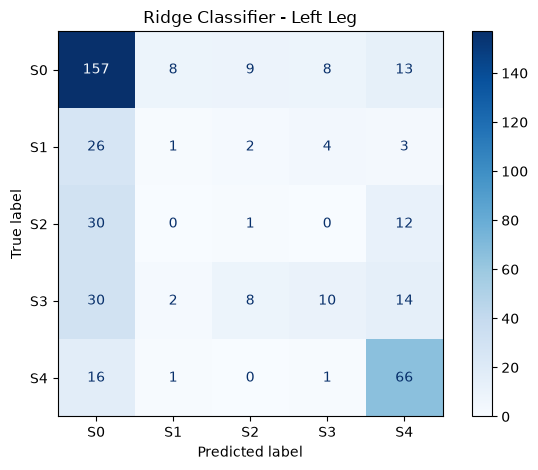

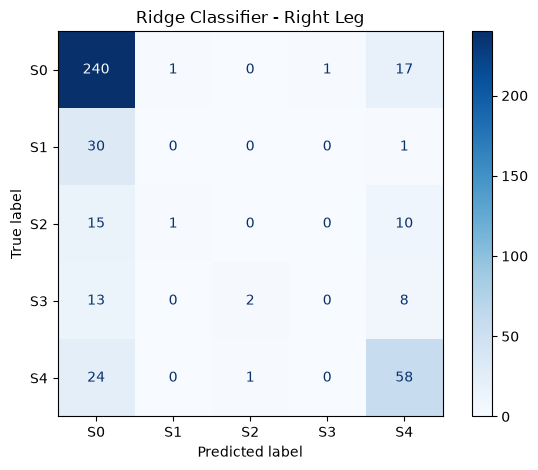

In [18]:
for side, actual, predicted in [
    ("Left", y_test["State_L"], pred_L),
    ("Right", y_test["State_R"], pred_R)
]:

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=range(N_STATES),
        display_labels=[f"S{i}" for i in range(N_STATES)],
        cmap="Blues"
    )

    plt.title(f"Ridge Classifier - {side} Leg")

    plt.tight_layout()

    plt.show()

In [19]:
test_results = pd.DataFrame({
    "Time_s": model_data.loc[
        test_mask, "end_time_s"
    ].to_numpy(),

    "recording_id": model_data.loc[
        test_mask, "recording_id"
    ].to_numpy(),

    "ActualState_L": y_test["State_L"].to_numpy(),
    "ActualState_R": y_test["State_R"].to_numpy(),

    "CandidateState_L": pred_L,
    "CandidateState_R": pred_R
})

test_results["BilateralState"] = (
    "L"
    + test_results["CandidateState_L"].astype(str)
    + "_R"
    + test_results["CandidateState_R"].astype(str)
)

# Display the first 5 predictions from each recording

predictions_per_movement = (
    test_results
    .groupby("recording_id", sort=False)
    .head(10)
)

display(predictions_per_movement)

,Time_s,recording_id,ActualState_L,ActualState_R,CandidateState_L,CandidateState_R,BilateralState
0,0.1995,abduction_z5,0,0,0,0,L0_R0
1,0.2994,abduction_z5,0,0,0,0,L0_R0
2,0.3994,abduction_z5,0,0,2,0,L2_R0
3,0.4994,abduction_z5,0,0,0,0,L0_R0
4,0.5994,abduction_z5,0,0,0,0,L0_R0
5,0.6994,abduction_z5,0,0,2,0,L2_R0
6,0.7994,abduction_z5,0,1,1,0,L1_R0
7,0.8993,abduction_z5,0,1,1,0,L1_R0
8,0.9993,abduction_z5,0,2,2,0,L2_R0
9,1.0993,abduction_z5,0,3,0,4,L0_R4


In [20]:
MAX_STATE_JUMP = 3

test_results["AcceptedState_L"] = 0
test_results["AcceptedState_R"] = 0
test_results["FaultFlag"] = False

for recording_id, group in test_results.groupby(
    "recording_id",
    sort=False
):

    prev_L = None
    prev_R = None

    group = group.sort_values("Time_s")

    for index, row in group.iterrows():

        cand_L = int(row["CandidateState_L"])
        cand_R = int(row["CandidateState_R"])

        if prev_L is None:
            prev_L = cand_L
            prev_R = cand_R
            fault = False

        else:
            fault = (
                abs(cand_L - prev_L) > MAX_STATE_JUMP
                or abs(cand_R - prev_R) > MAX_STATE_JUMP
            )

            if not fault:
                prev_L = cand_L
                prev_R = cand_R

        test_results.loc[index, "AcceptedState_L"] = prev_L
        test_results.loc[index, "AcceptedState_R"] = prev_R
        test_results.loc[index, "FaultFlag"] = fault

print(
    "Rejected transitions:",
    test_results["FaultFlag"].sum()
)

Rejected transitions: 228


In [21]:
def state_to_motor_command(state):
    return state / (N_STATES - 1)


test_results["MotorCommand_L"] = (
    test_results["AcceptedState_L"]
    .apply(state_to_motor_command)
)

test_results["MotorCommand_R"] = (
    test_results["AcceptedState_R"]
    .apply(state_to_motor_command)
)

display(test_results.head(10))

,Time_s,recording_id,ActualState_L,ActualState_R,CandidateState_L,CandidateState_R,BilateralState,AcceptedState_L,AcceptedState_R,FaultFlag,MotorCommand_L,MotorCommand_R
0,0.1995,abduction_z5,0,0,0,0,L0_R0,0,0,False,0.00,0.0
1,0.2994,abduction_z5,0,0,0,0,L0_R0,0,0,False,0.00,0.0
2,0.3994,abduction_z5,0,0,2,0,L2_R0,2,0,False,0.50,0.0
3,0.4994,abduction_z5,0,0,0,0,L0_R0,0,0,False,0.00,0.0
4,0.5994,abduction_z5,0,0,0,0,L0_R0,0,0,False,0.00,0.0
5,0.6994,abduction_z5,0,0,2,0,L2_R0,2,0,False,0.50,0.0
6,0.7994,abduction_z5,0,1,1,0,L1_R0,1,0,False,0.25,0.0
7,0.8993,abduction_z5,0,1,1,0,L1_R0,1,0,False,0.25,0.0
8,0.9993,abduction_z5,0,2,2,0,L2_R0,2,0,False,0.50,0.0
9,1.0993,abduction_z5,0,3,0,4,L0_R4,2,0,True,0.50,0.0


In [22]:
# Calculate whether both leg states were predicted correctly

test_results["Correct_Bilateral"] = (
    (test_results["ActualState_L"] == test_results["CandidateState_L"])
    &
    (test_results["ActualState_R"] == test_results["CandidateState_R"])
)

# Calculate bilateral accuracy for each recording

movement_accuracy = (
    test_results
    .groupby("recording_id")["Correct_Bilateral"]
    .mean()
    .mul(100)
    .round(2)
)

print("Bilateral Accuracy by Movement (%):")

display(movement_accuracy)

Bilateral Accuracy by Movement (%):


recording_id
abduction_z5    51.28
elevating_z5    41.05
flexing_z5      62.99
sitting_z5      40.35
walking_z5      16.92
Name: Correct_Bilateral, dtype: float64

In [23]:
from sklearn.metrics import f1_score

# Calculate Macro F1 for the left leg
f1_left = f1_score(
    y_test["State_L"],
    pred_L,
    labels=range(N_STATES),
    average="macro",
    zero_division=0
)

# Calculate Macro F1 for the right leg
f1_right = f1_score(
    y_test["State_R"],
    pred_R,
    labels=range(N_STATES),
    average="macro",
    zero_division=0
)

# Calculate average Macro F1
f1_average = (f1_left + f1_right) / 2

print("RIDGE CLASSIFIER - F1 SCORES")

print(f"Left-leg Macro F1: {f1_left:.4f}")

print(f"Right-leg Macro F1: {f1_right:.4f}")

print(f"Average Macro F1: {f1_average:.4f}")

RIDGE CLASSIFIER - F1 SCORES
Left-leg Macro F1: 0.3365
Right-leg Macro F1: 0.2963
Average Macro F1: 0.3164
